## Spam Classification Project
We use TF-IDF + logistic Regression for classification.
TF-IDF provide the a specific frequency number of each word in an email
Logistic regression take these frequency number of each email and them classifi that it is a spam or not spam.

## About Data-Set
We have two columns:
 email and other one label that contain 0 or 1 if the email is a spam the the label is 1 other 0 

## All important Imports

In [63]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report


import matplotlib.pyplot as plt

## 1. Load the Dataset
Reading the CSV file into a pandas DataFrame. Each row is one email with its label.

In [13]:
data_frame = pd.read_csv("spam_or_not_spam.csv")

## 2. Explore the Data
First, a quick look at the size of the dataset. It has **3000 rows and 2 columns**.

In [14]:
print("sahpe of the data (rows, columns):", data_frame.shape)

sahpe of the data (rows, columns): (3000, 2)


Checking the column names: `email` (the text) and `label` (0 = not spam, 1 = spam).

In [15]:
print("all Columns in the data: ", data_frame.columns.tolist())

all Columns in the data:  ['email', 'label']


Checking data types and non-null counts. The `email` column has 2999 non-null values out of 3000, so one email is missing.

In [16]:
print("Data Information")
print(data_frame.info())

Data Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   email   2999 non-null   object
 1   label   3000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 47.0+ KB
None


## 3. Data Cleaning
**Missing values:** counting nulls in each column. Only `email` has 1 missing value.

In [17]:
print("Total null values in the data set")

print( data_frame.isnull().sum())

Total null values in the data set
email    1
label    0
dtype: int64


Filling the missing email with the most frequent email text (`mode`), because the vectorizer cannot process an empty value. After this step there are no null values left.

In [18]:
data_frame["email"] = data_frame["email"].fillna(data_frame["email"].mode()[0])

print("After handling the Null Values")


print( data_frame.isnull().sum())

After handling the Null Values
email    0
label    0
dtype: int64


**Duplicate rows:** counting repeated rows. There are **127 duplicates**. Duplicates are a problem because the same email could appear in both the training and the test set, which would make the test score look better than it really is.

In [19]:
print("Duplicate Rows In data Set")
print("total Duplicated Values:", data_frame.duplicated().sum())

Duplicate Rows In data Set
total Duplicated Values: 127


Removing the duplicate rows. After this, 2873 unique emails remain.

In [21]:
data_frame.drop_duplicates(inplace=True)
print("after droping the Duplicate rows")

print("total Duplicated Values:", data_frame.duplicated().sum())

after droping the Duplicate rows
total Duplicated Values: 0


## 4. Label Distribution
Counting how many emails are spam and how many are not. There are **2445 not-spam** and **428 spam** emails, so the data is **imbalanced** (spam is only about 15%). This is why accuracy alone is not enough and precision, recall and F1 are also used. It is also the reason for `class_weight="balanced"` in the model.

In [22]:
print("label Distribution")

print(data_frame["label"].value_counts())

label Distribution
label
0    2445
1     428
Name: count, dtype: int64


## 5. Features and Target
- `X`: the email text (input)
- `Y`: the label (output the model must predict)

In [23]:
X = data_frame["email"]
Y = data_frame["label"]

## 6. Train/Test Split
Splitting the data into **80% training** and **20% testing**.
- `random_state=42` makes the split reproducible.
- `stratify=Y` keeps the same spam ratio in both parts, which matters because spam is the smaller class.

In [25]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, 
    Y,
    test_size = 0.2,
    random_state=42,
    stratify = Y
)

Confirming the split sizes: **2298 training** emails and **575 test** emails.

In [26]:
print("Traing Data: ", len(X_train))
print("Testing Data: ", len(X_test))

Traing Data:  2298
Testing Data:  575


## 7. Convert Text to Numbers with TF-IDF
A model cannot read raw text, so TF-IDF gives every word a weight. A word gets a high weight when it appears often in an email but is rare across all emails.

Settings used:
- `lowercase=True`: treat "FREE" and "free" as the same word
- `stop_words="english"`: remove very common words such as "the" and "is"
- `ngram_range=(1,2)`: use single words and two-word phrases (for example "click here")
- `max_features=50000`: keep only the 50,000 most important terms

The vectorizer is **fitted on the training data only** (`fit_transform`) and then only applied to the test data (`transform`). This prevents information from the test set leaking into the model. Both matrices have 50,000 columns, one per term.

In [52]:
TF_IDF = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1,2),
    max_features=50000 
)

X_train_TF_IDF = TF_IDF.fit_transform(X_train)

X_test_TF_IDF = TF_IDF.transform(X_test)

print("shape of X_train_TF_IDF: ", X_train_TF_IDF.shape)
print("shape of X_test_TF_IDF: ", X_test_TF_IDF.shape)

shape of X_train_TF_IDF:  (2298, 50000)
shape of X_test_TF_IDF:  (575, 50000)


## 8. Build the Logistic Regression Model
Logistic Regression is a classification algorithm. It calculates a weighted sum of the word scores and passes it through the sigmoid function to get the probability that an email is spam.

Settings used:
- `max_iter=1000`: enough iterations for the optimizer to converge with 50,000 features
- `class_weight="balanced"`: gives the rare spam class more importance during training
- `random_state=42`: reproducible results

In [53]:
model = LogisticRegression(
    max_iter = 1000,
    class_weight="balanced",
    random_state = 42
)


     

## 9. Train the Model
Fitting the model on the TF-IDF training matrix and the training labels. During training the model learns a weight for every term.

In [55]:
model.fit(X_train_TF_IDF, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


## 10. Predict on the Test Data
Using the trained model to predict the labels of the unseen test emails.

In [56]:
Y_prediction = model.predict(X_test_TF_IDF)

## 11. Model Evaluation
Calculating the four main metrics by comparing the real labels with the predictions:
- **Accuracy:** share of all emails classified correctly
- **Precision:** of the emails predicted as spam, how many really are spam
- **Recall:** of the real spam emails, how many were found
- **F1 score:** balance between precision and recall

In [57]:
accuracy = accuracy_score(Y_test, Y_prediction)

precision = precision_score(Y_test, Y_prediction)

recall = recall_score(Y_test, Y_prediction)

f1 = f1_score(Y_test, Y_prediction)

Printing the metrics. The model reaches about **98.4% accuracy, 97.5% precision, 91.9% recall and 94.6% F1**. Precision is higher than recall, so the model rarely marks a normal email as spam but misses some real spam.

In [58]:
print("MODEL PERFORMANCE")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

MODEL PERFORMANCE
Accuracy : 0.9843478260869565
Precision: 0.9753086419753086
Recall   : 0.9186046511627907
F1 Score : 0.9461077844311377


The classification report shows precision, recall and F1 for each class separately. Spam is the smaller class, so its recall (0.92) is a bit lower than that of the not-spam class (1.00).

In [59]:
print(
    classification_report(
        Y_test,
        Y_prediction,
        target_names = ["Not Sapm", "Spam"]
    ) 
)

              precision    recall  f1-score   support

    Not Sapm       0.99      1.00      0.99       489
        Spam       0.98      0.92      0.95        86

    accuracy                           0.98       575
   macro avg       0.98      0.96      0.97       575
weighted avg       0.98      0.98      0.98       575



**Confusion matrix:** rows are the actual classes and columns are the predicted classes.
- 487 not-spam emails were correctly predicted as not spam
- 2 not-spam emails were wrongly predicted as spam (false positives)
- 7 spam emails were missed (false negatives)
- 79 spam emails were correctly caught

In [65]:
cm = confusion_matrix(Y_test, Y_prediction)

print(cm)

[[487   2]
 [  7  79]]


Plotting the confusion matrix as a heatmap with the counts written in each cell.

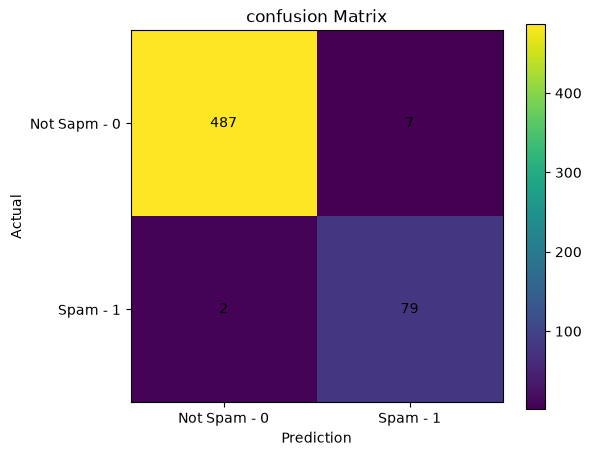

In [77]:
plt.figure(figsize=(6,5))

plt.imshow(cm)

plt.title("confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Not Spam - 0" , "Spam - 1"]

)

plt.yticks(
    [0, 1],
    ["Not Sapm - 0", "Spam - 1"]

)

for i in range(2):
    for j in range(2):
        plt.text(
            i,
            j,
            cm[i, j],
            ha = "center",
            va = "center"
        )

plt.colorbar()
plt.show()

## 12. Predict a New Email
Testing the model on a new email. The email must pass through the **same fitted TF-IDF vectorizer** (`transform`) before prediction. `predict` gives the class and `predict_proba` gives the probability. The sample promotional email is classified as **spam** with a probability of about 0.94.

In [84]:
new_email = [
    "thank you for shopping with us gifts for all occasions free gift with NUMBER NUMBER purchase for a limited time only receive this NUMBER plush santa bear free with your purchase of NUMBER NUMBER or more when your order totals NUMBER NUMBER or more order must be NUMBER NUMBER or more before shipping and handling this santa bear is added to your cart for free while supplies last mary s store would like to thank you for being a valued customer as our way of saying thanks to you the customer we are offering a NUMBER discount on all purchases made during the month of november just enter the word thanks in the discount code box during checkout to receive your automatic NUMBER discount hyperlink click here hyperlink to enter hyperlink mary s store if you do not wish to receive further discounts please hyperlink click here and type remove in the subject line"
]


new_email_TF_IDF = TF_IDF.transform(new_email)

prediction = model.predict(new_email_TF_IDF)

prob = model.predict_proba(new_email_TF_IDF)


if prediction[0] != 1 :
    print("This email is NOT_SPAM")
    print("probability : ", prob[0][0])
else:
    print("This email is SPAM")
    print("probability : ", prob[0][1])



This email is SPAM
probability :  0.9422610774953568
